In [3]:
!pip install -r C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\requirements.txt

  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.5 MB 6.9 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.5 MB 5.5 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.5 MB 6.2 MB/s eta 0:00:01
   ---------------------- ----------------- 5.2/9.5 MB 6.6 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 7.0 MB/s eta 0:00:01
   ------------------------------------ --- 8.7/9.5 MB 7.1 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 7.0 MB/s  0:00:01
Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl (12.7 MB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   --


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

def seed_everything(seed=RANDOM_STATE):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(RANDOM_STATE)
print(f"Random seed set to: {RANDOM_STATE}")

Random seed set to: 42


In [5]:
# Define project root and data paths 
PROJECT_ROOT = Path(".").resolve().parent if Path(".").resolve().name == "notebooks" else Path(".").resolve() 
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "diabetic_data.csv" 
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed" 
# Create directories if they don't exist 
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True) 
print(f"Raw data location: {RAW_DATA_PATH}") 
print(f"Processed output location: {PROCESSED_DATA_DIR}")

Raw data location: C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\data\raw\diabetic_data.csv
Processed output location: C:\Users\aruna\OneDrive\Documents\upgrad\Capstone-Implementation-Package-MLOps\data\processed


# Stage 1 - Business & Data Understanding, EDA, Methodology

## Task 1.1 - Business Understanding

### 1.1.1 Business objective and justification

The objective is to identify diabetic inpatients who are at higher risk of readmission within 30 days of discharge. At discharge, care coordinators and clinical teams could use risk estimates to prioritize follow-up calls, medication reviews, and appointments. These interventions may help prevent some readmissions and reduce associated costs and pressure on hospital beds. A prediction alone does not improve outcomes; appropriate clinical action and evaluation are essential.

### 1.1.2 Measurable success criteria and metric choice

The positive class is a minority, so accuracy alone can be misleading. For this educational project, the model-selection target is validation ROC-AUC of at least **0.70**. Recall is the operational watch metric because missed readmissions are costly; we will also report PR-AUC, precision, F1-score, and confusion matrices. Any recall target and decision threshold will be selected on validation data and treated as project targets, not clinical standards. The test set will be used only for final evaluation.

### 1.1.3 Scope, constraints, and assumptions

- Use the supplied de-identified historical encounter dataset and run the initial workflow locally.
- Use a local MLflow file store for experiment tracking and model registry.
- Treat the target as imbalanced and account for repeated encounters per patient.
- The dataset is historical (1999-2008); results may not generalize to current clinical practice.
- This is an educational exercise, not a clinical decision tool. Real use would require clinical, external, fairness, privacy, and regulatory validation.

Dataset source: [UCI Diabetes 130-US Hospitals Dataset](https://doi.org/10.24432/C5230J).

## Task 1.2 - Dataset Understanding

In [ ]:
# Load the raw dataset. Preserve the literal category 'None'; convert '?' and blank fields to missing values.
data = pd.read_csv(
    RAW_DATA_PATH,
    na_values=["?", ""],
    keep_default_na=False,
    low_memory=False,
)

display(data.head(15))
data.info()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
5,35754,82637451,Caucasian,Male,[50-60),NaN,2,1,2,3,NaN,NaN,31,6,16,0,0,0,414,411,250,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes,>30
6,55842,84259809,Caucasian,Male,[60-70),NaN,3,1,2,4,NaN,NaN,70,1,21,0,0,0,414,411,V45,7,None,None,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
7,63768,114882984,Caucasian,Male,[70-80),NaN,1,1,7,5,NaN,NaN,73,0,12,0,0,0,428,492,250,8,None,None,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,>30
8,12522,48330783,Caucasian,Female,[80-90),NaN,2,1,4,13,NaN,NaN,68,2,28,0,0,0,398,427,38,8,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO
9,15738,63555939,Caucasian,Female,[90-100),NaN,3,3,4,12,NaN,InternalMedicine,33,3,18,0,0,0,434,198,486,8,None,None,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

### 1.2.1 Dataset structure, target derivation, and patients versus encounters

Each row represents a hospital encounter. A patient may have multiple encounters, so the patient count is lower than the encounter count. For the binary outcome, `<30` is positive (1); `>30` and `NO` are negative (0). The raw encounter-level distribution is reported below; it will be recalculated after Stage 2 cleaning.

Dataset shape: (101766, 50)
Number of encounter rows: 101766
Unique encounters: 101766
Unique patients: 71518
Duplicate encounter IDs: 0

Original readmission labels:


,encounters
readmitted,
NO,54864
>30,35545
<30,11357



Binary target distribution (raw encounters):


,encounters,percentage
readmitted_30d,,
0,90409,88.84
1,11357,11.16


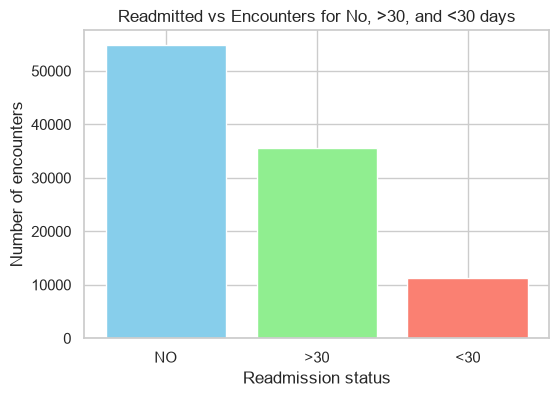

In [ ]:
print("Dataset shape:", data.shape)
print("Number of encounter rows:", len(data))
print("Unique encounters:", data["encounter_id"].nunique())
print("Unique patients:", data["patient_nbr"].nunique())
print("Duplicate encounter IDs:", data["encounter_id"].duplicated().sum())

valid_labels = {"<30", ">30", "NO"}
missing_labels = data["readmitted"].isna().sum()
unexpected_labels = set(data["readmitted"].dropna().unique()) - valid_labels
if missing_labels or unexpected_labels:
    raise ValueError(
        f"Missing readmission labels: {missing_labels}; "
        f"unexpected labels: {unexpected_labels}"
    )

# Keep the raw outcome and features intact; add the binary outcome on an EDA copy.
eda = data.copy()
eda["readmitted_30d"] = (eda["readmitted"] == "<30").astype(int)

print("\nOriginal readmission labels:")
display(data["readmitted"].value_counts(dropna=False).to_frame("encounters"))

target_counts = eda["readmitted_30d"].value_counts().reindex([0, 1], fill_value=0)
target_summary = pd.DataFrame(
    {
        "encounters": target_counts,
        "percentage": (target_counts / len(eda) * 100).round(2),
    }
)
target_summary.index.name = "readmitted_30d"
print("\nBinary target distribution (raw encounters):")
display(target_summary)

# Step 5 — readmitted vs encounters for No, >30, and <30 days
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
readmitted_counts = eda["readmitted"].value_counts().reindex(["NO", ">30", "<30"], fill_value=0)
plt.bar(readmitted_counts.index.astype(str), readmitted_counts.values, color=["skyblue", "lightgreen", "salmon"])
plt.xlabel("Readmission status")
plt.ylabel("Number of encounters")
plt.title("Readmitted vs Encounters for No, >30, and <30 days")
plt.show()

### 1.2.2 Feature types and data quality

The table below reports each column's pandas data type, missing count and percentage, and number of distinct non-missing values. Integer-coded admission and discharge fields are categorical codes, not necessarily continuous measures. The identifiers identify encounters and patients and will not be model predictors.

In [24]:
quality = pd.DataFrame(
    {
        "data_type": data.dtypes.astype(str),
        "missing_count": data.isna().sum(),
        "missing_percent": (data.isna().mean() * 100).round(2),
        "unique_values": data.nunique(dropna=True),
    }
).sort_values("missing_percent", ascending=False)

print("Column counts by pandas data type:")
display(data.dtypes.astype(str).value_counts().rename_axis("data_type").to_frame("column_count"))

print("Column-by-column data quality (all columns):")
with pd.option_context("display.max_rows", None):
    display(quality)

print("Exact duplicate rows:", data.duplicated().sum())

Column counts by pandas data type:


,column_count
data_type,
str,37
int64,13


Column-by-column data quality (all columns):


,data_type,missing_count,missing_percent,unique_values
weight,str,98569,96.86,9
medical_specialty,str,49949,49.08,72
payer_code,str,40256,39.56,17
race,str,2273,2.23,5
diag_3,str,1423,1.40,789
diag_2,str,358,0.35,748
diag_1,str,21,0.02,716
admission_type_id,int64,0,0.00,8
patient_nbr,int64,0,0.00,71518
encounter_id,int64,0,0.00,101766


Exact duplicate rows: 0


#### Missingness interpretation

In this CSV, `-` is the missing-value marker. The lab values `None` mean that the test was not measured, so the loader preserves `None` as a category instead of converting it to NaN. In the raw dataset, `weight` is approximately 96.86% missing, `medical_specialty` 49.08%, `payer_code` 39.56%, and `race` 2.23%. These observations inform Stage 2 cleaning; they do not by themselves define every column's treatment.

In [25]:
print("Raw readmission label counts:")
display(data["readmitted"].value_counts(dropna=False).to_frame("encounters"))

print("Lab-test categories (including 'None' = not measured):")
for column in ["max_glu_serum", "A1Cresult"]:
    print(f"\n{column}:")
    display(data[column].value_counts(dropna=False).to_frame("encounters"))

Raw readmission label counts:


,encounters
readmitted,
NO,54864
>30,35545
<30,11357


Lab-test categories (including 'None' = not measured):

max_glu_serum:


,encounters
max_glu_serum,
None,96420
Norm,2597
>200,1485
>300,1264



A1Cresult:


,encounters
A1Cresult,
None,84748
>8,8216
Norm,4990
>7,3812


## Task 1.3 - Exploratory Data Analysis

### 1.3.1 Univariate analysis: target imbalance

The binary target plot shows the raw encounter-level class imbalance. Accuracy alone is misleading: a model predicting only the majority class can have high accuracy while failing to identify any 30-day readmissions.

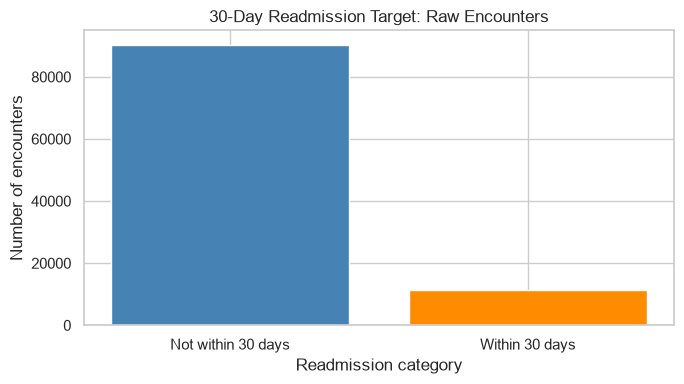

In [26]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    ["Not within 30 days", "Within 30 days"],
    target_counts.values,
    color=["steelblue", "darkorange"],
)
ax.set_title("30-Day Readmission Target: Raw Encounters")
ax.set_xlabel("Readmission category")
ax.set_ylabel("Number of encounters")

plt.tight_layout()
plt.show()

### 1.3.1 Univariate analysis: numeric distributions

The following plots show four numeric encounter features. Numeric summaries are included to support observations about their ranges and skew.

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0


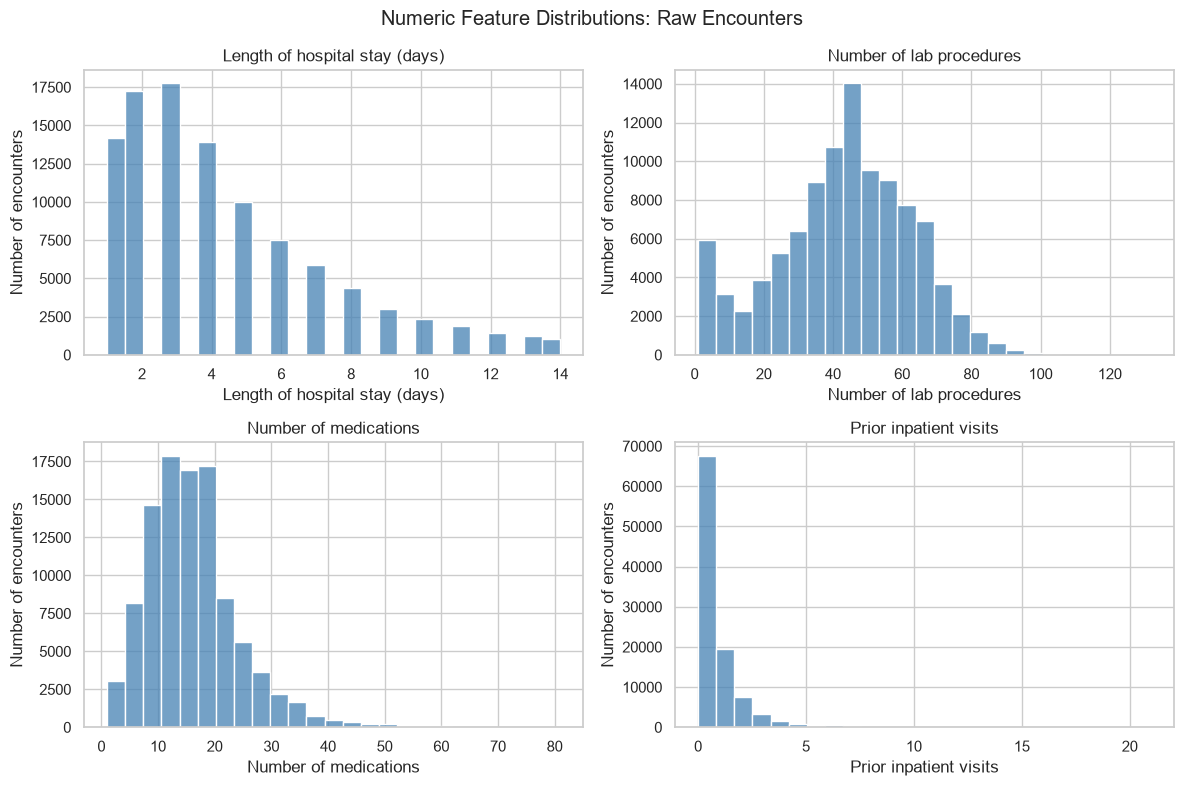

In [27]:
numeric_columns = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_medications",
    "number_inpatient",
]
labels = [
    "Length of hospital stay (days)",
    "Number of lab procedures",
    "Number of medications",
    "Prior inpatient visits",
]

display(data[numeric_columns].describe().T.round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, label, ax in zip(numeric_columns, labels, axes.flat):
    sns.histplot(data=data, x=column, bins=25, color="steelblue", ax=ax)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel("Number of encounters")

fig.suptitle("Numeric Feature Distributions: Raw Encounters")
plt.tight_layout()
plt.show()

,prior_inpatient_group,encounters,readmission_rate_percent
0,0,67630,8.44
1,1,19521,12.92
2,2,7566,17.43
3,3,3411,20.29
4,4+,3638,30.70


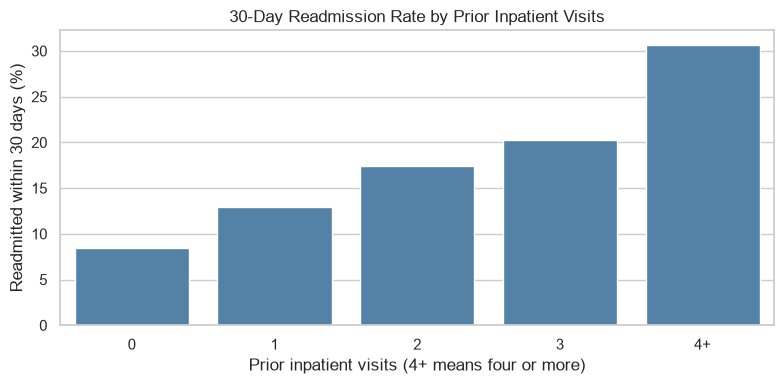

In [28]:
eda["prior_inpatient_group"] = pd.cut(
    eda["number_inpatient"],
    bins=[-1, 0, 1, 2, 3, float("inf")],
    labels=["0", "1", "2", "3", "4+"],
)

visit_summary = (
    eda.groupby("prior_inpatient_group", observed=True)["readmitted_30d"]
    .agg(encounters="size", readmission_rate="mean")
    .reset_index()
)
visit_summary["readmission_rate_percent"] = (
    visit_summary["readmission_rate"] * 100
).round(2)

display(
    visit_summary[
        ["prior_inpatient_group", "encounters", "readmission_rate_percent"]
    ]
)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=visit_summary,
    x="prior_inpatient_group",
    y="readmission_rate_percent",
    color="steelblue",
    ax=ax,
)
ax.set_title("30-Day Readmission Rate by Prior Inpatient Visits")
ax.set_xlabel("Prior inpatient visits (4+ means four or more)")
ax.set_ylabel("Readmitted within 30 days (%)")

plt.tight_layout()
plt.show()

### 1.3.3 Visualizations and written interpretation

- **Target:** In the raw data, 11.16% of encounters are readmitted within 30 days. The target is imbalanced, so accuracy alone would hide missed positive cases.
- **Hospital stay:** Median stay is 4 days; the middle 50% is between 2 and 6 days.
- **Lab procedures:** The median is 44; the middle 50% is between 31 and 57.
- **Medications:** The median is 15 medications per encounter, with a long upper tail.
- **Prior inpatient visits:** The median is zero, and most encounters have no prior inpatient visits.
- **Bivariate relationship:** The raw 30-day readmission rate increases across prior-inpatient groups: approximately 8.44% for 0 visits, 12.92% for 1, 17.43% for 2, 20.29% for 3, and 30.70% for 4 or more. This is an association, not evidence that prior visits cause readmission.

These EDA results use raw encounters, including repeat patients. The rates and distributions may change after the Stage 2 cleaning rules are applied.

## Task 1.4 - Methodology Design

### 1.4.1 End-to-end MLOps workflow / architecture

The planned lifecycle is **validate - train - track - register - deploy - monitor - retrain - govern**:

1. Validate input schema, labels, and data-quality assumptions.
2. Prepare leakage-safe train, validation, and test partitions; train the Logistic Regression baseline and XGBoost model.
3. Track parameters, metrics, and model artifacts in MLflow.
4. Register the model selected using validation ROC-AUC and promote the selected version to the production alias.
5. Serve the complete preprocessing-and-model pipeline through a validated FastAPI endpoint and container.
6. Monitor feature and prediction drift; monitor performance when outcomes become available.
7. Retrain only when defined drift/performance signals justify it, then evaluate the candidate before promotion.
8. Record model versions, decisions, dependencies, and operational evidence for governance.

The initial implementation uses local execution and a local MLflow file store, as specified for this capstone.

### 1.4.2 Data-leakage-prevention strategy

- Apply the specified expired/hospice exclusion and keep one encounter per patient before splitting, so a patient's encounters cannot appear in different partitions.
- The CSV has no encounter-date column, so the retained -first- row is the first row in file order; chronological first encounter cannot be verified from this file. Document this limitation.
- Split the cleaned data into stratified train, validation, and test sets with a fixed random seed. Confirm patient IDs do not overlap across splits.
- Fit imputers, scalers, encoders, learned category groupings, and any resampling only on the training data, inside the model pipeline. Apply the fitted pipeline to validation and test data without refitting.
- Use validation data for model selection and threshold decisions. Use the test set once for final evaluation.
- Exclude the raw readmission label, derived target, patient ID, and encounter ID from model predictors. Use only information available at discharge.

Full-dataset EDA here is descriptive. Any data-dependent preprocessing or modeling decisions must be learned from the training split only.